In [1]:
import pandas
import numpy
import matplotlib.pyplot as plt
import seaborn

In [21]:
df = pandas.read_csv("GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz", 
sep="\t", 
header=2, 
index_col='Description')

In [3]:
df.shape

(74628, 69)

In [4]:
df.head()

,Name,Adipose_Subcutaneous,Adipose_Visceral_Omentum,Adrenal_Gland,Artery_Aorta,Artery_Coronary,Artery_Tibial,Bladder,Brain_Amygdala,Brain_Anterior_cingulate_cortex_BA24,...,Spleen,Stomach,Stomach_Mixed_Cell,Stomach_Mucosa,Stomach_Muscularis,Testis,Thyroid,Uterus,Vagina,Whole_Blood
Description,,,,,,,,,,,,,,,,,,,,,
DDX11L16,ENSG00000290825.2,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.011780,0.000000,...,0.00000,0.00000,0.014928,0.012652,0.015991,0.073208,0.00000,0.00000,0.00000,0.0000
DDX11L1,ENSG00000223972.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.00000,0.0000
WASH7P,ENSG00000310526.1,2.45431,1.9053,1.75253,2.3178,2.21944,1.66539,3.14825,0.565228,0.652863,...,5.04503,2.04517,1.868420,1.507490,1.909350,3.126710,4.01324,4.92657,3.85789,2.2098
MIR1302-2HG,ENSG00000243485.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.036257,0.00000,0.00000,0.00000,0.0000
FAM138A,ENSG00000237613.3,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.012860,0.013432,...,0.00000,0.00000,0.015325,0.013091,0.018168,0.000000,0.00000,0.00000,0.00000,0.0000


In [22]:
df = df.drop("Name", axis=1)

In [23]:
df.shape

(74628, 68)

In [25]:
df = numpy.log10(df)

/home/davidb/miniforge3/envs/srpp_env/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


<Axes: ylabel='Count'>

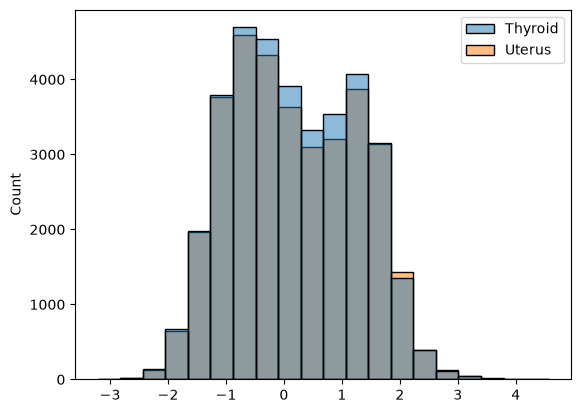

In [32]:
seaborn.histplot([df['Thyroid'], df['Uterus']], bins=20)

<Axes: xlabel='NOVA2', ylabel='TUBB'>

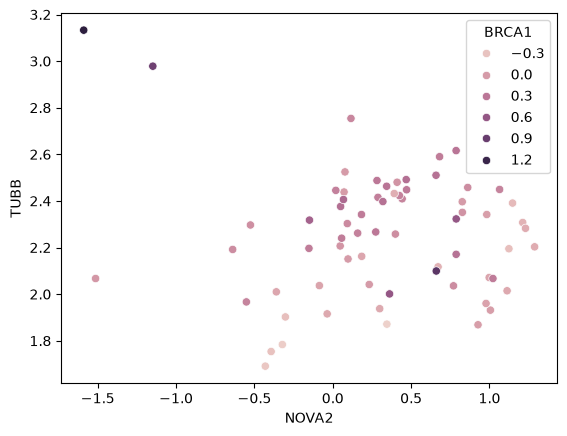

In [38]:
seaborn.scatterplot(x=df.loc['NOVA2'], y=df.loc['TUBB'], hue=df.loc['BRCA1'])

In [45]:
10 ** df.loc['BRCA1']['Breast_Mammary_Tissue']

np.float64(1.18184)

In [43]:
df.columns

Index(['Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Adrenal_Gland',
       'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Bladder',
       'Brain_Amygdala', 'Brain_Anterior_cingulate_cortex_BA24',
       'Brain_Caudate_basal_ganglia', 'Brain_Cerebellar_Hemisphere',
       'Brain_Cerebellum', 'Brain_Cortex', 'Brain_Frontal_Cortex_BA9',
       'Brain_Hippocampus', 'Brain_Hypothalamus',
       'Brain_Nucleus_accumbens_basal_ganglia', 'Brain_Putamen_basal_ganglia',
       'Brain_Spinal_cord_cervical_c-1', 'Brain_Substantia_nigra',
       'Breast_Mammary_Tissue', 'Cells_Cultured_fibroblasts',
       'Cells_EBV-transformed_lymphocytes', 'Cervix_Ectocervix',
       'Cervix_Endocervix', 'Colon_Sigmoid', 'Colon_Transverse',
       'Colon_Transverse_Mixed_Cell', 'Colon_Transverse_Mucosa',
       'Colon_Transverse_Muscularis', 'Esophagus_Gastroesophageal_Junction',
       'Esophagus_Mucosa', 'Esophagus_Muscularis', 'Fallopian_Tube',
       'Heart_Atrial_Appendage', 'Heart_Left_Ventr

In [50]:
ann = pandas.read_csv("gencode.v47.annotation.chr22.gtf", sep='\t', header=None)

In [59]:
ann.head()

,chromosome,source,feature,start,end,idk,strand,idk2,description
0,chr22,HAVANA,gene,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; gene_type ""lncRNA..."
1,chr22,HAVANA,transcript,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
2,chr22,HAVANA,exon,10529036,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
3,chr22,HAVANA,exon,10527853,10528040,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
4,chr22,HAVANA,exon,10524345,10524446,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."


In [58]:
ann = ann.rename(columns={0: "chromosome", 
1: "source", 
2: "feature", 
3: "start", 
4: "end", 
5: "idk", 
6: "strand", 
7: "idk2", 
8: "description", })